## Transfer Learning with a Pretrained CNN

This notebook demonstrates transfer learning using a pre-trained `ResNet50V2` model on a custom dataset (cats vs dogs). We will follow these steps:

1.  **Import Libraries**: Set up the necessary Python libraries.
2.  **Download and Prepare Dataset**: Obtain and preprocess the 'cats vs dogs' dataset.
3.  **Data Augmentation**: Apply augmentation to improve model generalization.
4.  **Load Pretrained Model**: Load `ResNet50V2` without its top classification layer.
5.  **Freeze Base Layers**: Prevent the weights of the pre-trained model from being updated during the initial training phase.
6.  **Add Custom Classification Head**: Attach new layers for binary classification (cats vs dogs).
7.  **Compile and Train (Phase 1)**: Train the new classification head with frozen base layers.
8.  **Unfreeze and Fine-tune (Phase 2)**: Unfreeze some layers of the base model and fine-tune the entire model with a lower learning rate.
9.  **Evaluate Performance**: Assess the trained model's accuracy and loss.

In [1]:
# Cell 1: Import Required Libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import sys
!{sys.executable} -m pip install --upgrade importlib-resources

# After running this cell, please restart the Colab runtime (Runtime -> Restart runtime)
# and then run all cells from the beginning.

In [3]:
# Cell 2: Download and Extract Cats vs Dogs Dataset

import tensorflow_datasets as tfds

# Download the dataset
dataset, info = tfds.load(
    'cats_vs_dogs',
    with_info=True,
    as_supervised=True,
    download=True
)

print("Dataset downloaded successfully!")
print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.I01G50_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset downloaded successfully!
tfds.core.DatasetInfo(
    name='cats_vs_dogs',
    full_name='cats_vs_dogs/4.0.1',
    description="""
    A large set of images of cats and dogs. There are 1738 corrupted images that are dropped.
    """,
    homepage='https://www.microsoft.com/en-us/download/details.aspx?id=54765',
    data_dir='/root/tensorflow_datasets/cats_vs_dogs/4.0.1',
    file_format=tfrecord,
    download_size=786.67 MiB,
    dataset_size=1.04 GiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'image/filename': Text(shape=(), dtype=string),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=2),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=23262, num_shards=16>,
    }

In [4]:
# Cell 3: Check Dataset Information

train_data = dataset['train']

# Count total images
total_images = info.splits['train'].num_examples

print("Total images:", total_images)

# Display the class names
print("Class names:", info.features['label'].names)

Total images: 23262
Class names: ['cat', 'dog']


In [5]:
# Cell 4: Create Training and Validation Datasets

# Shuffle the dataset
dataset = dataset['train'].shuffle(
    buffer_size=1000,
    seed=42,
    reshuffle_each_iteration=False
)

# Take 2,500 images for our practical
small_dataset = dataset.take(2500)

# Split into training and validation
train_size = 2000

train_data = small_dataset.take(train_size)
validation_data = small_dataset.skip(train_size)

print("Training images:", train_size)
print("Validation images:", 500)

Training images: 2000
Validation images: 500


In [6]:
# Cell 5: Preprocess Images for ResNet50

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def preprocess_image(image, label):
    # Resize image
    image = tf.image.resize(image, IMG_SIZE)

    # Convert to float32
    image = tf.cast(image, tf.float32)

    # ResNet50 preprocessing
    image = preprocess_input(image)

    return image, label


# Apply preprocessing
train_data = train_data.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_data = validation_data.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Batch and optimize the datasets
train_data = train_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
validation_data = validation_data.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Image preprocessing completed!")
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image preprocessing completed!
Image size: (224, 224)
Batch size: 32


In [7]:
weights='imagenet'
include_top=False

In [8]:
# Cell 6: Load Pretrained ResNet50

base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

print("Pretrained ResNet50 loaded successfully!")
print("Number of layers:", len(base_model.layers))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Pretrained ResNet50 loaded successfully!
Number of layers: 175


In [9]:
# Cell 7: Freeze ResNet50 Layers

base_model.trainable = False

print("ResNet50 layers frozen!")
print("Trainable:", base_model.trainable)

# Count trainable and non-trainable parameters
trainable_params = sum(
    np.prod(v.shape) for v in base_model.trainable_weights
)

non_trainable_params = sum(
    np.prod(v.shape) for v in base_model.non_trainable_weights
)

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

ResNet50 layers frozen!
Trainable: False
Trainable parameters: 0
Non-trainable parameters: 23587712


In [10]:
# Cell 8: Build Transfer Learning Model

model = models.Sequential([
    # Pretrained ResNet50
    base_model,

    # Convert feature maps into a single feature vector
    layers.GlobalAveragePooling2D(),

    # Fully connected classification layer
    layers.Dense(128, activation='relu'),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output layer: 1 neuron for binary classification
    layers.Dense(1, activation='sigmoid')
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [11]:
# Cell 9: Compile the Transfer Learning Model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [12]:
# Cell 10: Train the Model with Frozen ResNet50

EPOCHS = 5

history_frozen = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS
)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 44s 460ms/step - accuracy: 0.8730 - loss: 0.2951 - val_accuracy: 0.9800 - val_loss: 0.0919
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 185ms/step - accuracy: 0.9760 - loss: 0.0889 - val_accuracy: 0.9820 - val_loss: 0.0569
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 172ms/step - accuracy: 0.9795 - loss: 0.0636 - val_accuracy: 0.9840 - val_loss: 0.0485
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 171ms/step - accuracy: 0.9830 - loss: 0.0500 - val_accuracy: 0.9880 - val_loss: 0.0415
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 11s 165ms/step - accuracy: 0.9890 - loss: 0.0384 - val_accuracy: 0.9840 - val_loss: 0.0413


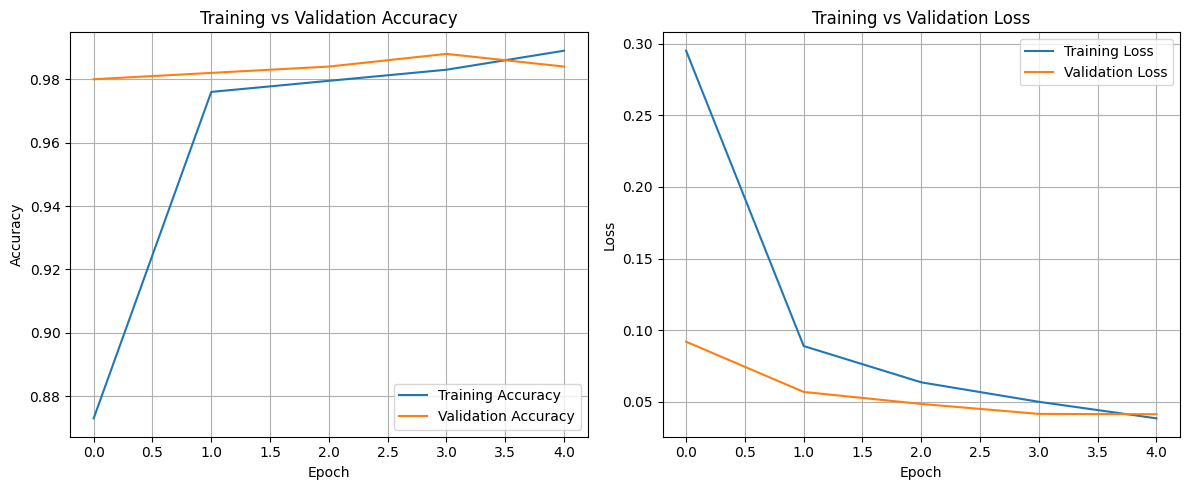

In [13]:
# Cell 11: Plot Training and Validation Performance

plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)

plt.plot(
    history_frozen.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_frozen.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)


# Loss plot
plt.subplot(1, 2, 2)

plt.plot(
    history_frozen.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_frozen.history['val_loss'],
    label='Validation Loss'
)

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
# Cell 12: Evaluate Frozen Model

loss_frozen, accuracy_frozen = model.evaluate(validation_data)

print("\nFrozen Model Results")
print("--------------------")
print("Validation Loss:", round(loss_frozen, 4))
print("Validation Accuracy:", round(accuracy_frozen * 100, 2), "%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 86ms/step - accuracy: 0.9840 - loss: 0.0413

Frozen Model Results
--------------------
Validation Loss: 0.0413
Validation Accuracy: 98.4 %


In [15]:
# Cell 13: Unfreeze the Last 20 Layers of ResNet50

base_model.trainable = True

# Freeze all layers except the last 20
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Check how many layers are trainable
trainable_layers = sum(
    1 for layer in base_model.layers if layer.trainable
)

print("Total ResNet50 layers:", len(base_model.layers))
print("Trainable ResNet50 layers:", trainable_layers)
print("Frozen ResNet50 layers:", len(base_model.layers) - trainable_layers)

Total ResNet50 layers: 175
Trainable ResNet50 layers: 20
Frozen ResNet50 layers: 155


In [16]:
# Cell 14: Recompile Model for Fine-Tuning

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model recompiled for fine-tuning!")
print("Learning rate: 0.00001")

Model recompiled for fine-tuning!
Learning rate: 0.00001


In [17]:
# Cell 15: Fine-Tune the ResNet50 Model

EPOCHS_FINE_TUNE = 5

history_finetune = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=EPOCHS_FINE_TUNE
)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 43s 390ms/step - accuracy: 0.9795 - loss: 0.0571 - val_accuracy: 0.9820 - val_loss: 0.0537
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 184ms/step - accuracy: 0.9925 - loss: 0.0322 - val_accuracy: 0.9840 - val_loss: 0.0471
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 187ms/step - accuracy: 0.9935 - loss: 0.0226 - val_accuracy: 0.9840 - val_loss: 0.0437
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 177ms/step - accuracy: 0.9985 - loss: 0.0139 - val_accuracy: 0.9860 - val_loss: 0.0447
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 173ms/step - accuracy: 0.9995 - loss: 0.0095 - val_accuracy: 0.9840 - val_loss: 0.0436


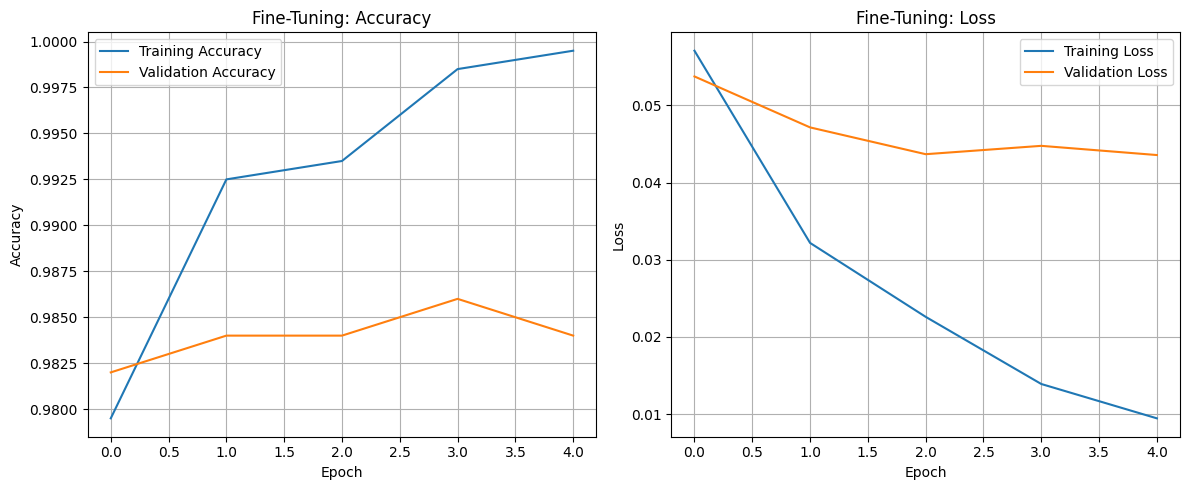

In [18]:
# Cell 16: Plot Fine-Tuning Performance

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    history_finetune.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_finetune.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('Fine-Tuning: Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)


# Loss
plt.subplot(1, 2, 2)

plt.plot(
    history_finetune.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_finetune.history['val_loss'],
    label='Validation Loss'
)

plt.title('Fine-Tuning: Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [19]:
# Cell 17: Evaluate Fine-Tuned Model

loss_finetune, accuracy_finetune = model.evaluate(validation_data)

print("\nFine-Tuned Model Results")
print("------------------------")
print("Validation Loss:", round(loss_finetune, 4))
print("Validation Accuracy:", round(accuracy_finetune * 100, 2), "%")

16/16 ━━━━━━━━━━━━━━━━━━━━ 5s 105ms/step - accuracy: 0.9840 - loss: 0.0436

Fine-Tuned Model Results
------------------------
Validation Loss: 0.0436
Validation Accuracy: 98.4 %


In [20]:
# Cell 18: Compare Frozen Model and Fine-Tuned Model

print("======================================")
print("   TRANSFER LEARNING PERFORMANCE")
print("======================================")

print(f"Frozen ResNet50 Accuracy     : {accuracy_frozen * 100:.2f}%")
print(f"Fine-Tuned ResNet50 Accuracy : {accuracy_finetune * 100:.2f}%")

improvement = (accuracy_finetune - accuracy_frozen) * 100

print("--------------------------------------")
print(f"Accuracy Change              : {improvement:+.2f}%")
print("======================================")

   TRANSFER LEARNING PERFORMANCE
Frozen ResNet50 Accuracy     : 98.40%
Fine-Tuned ResNet50 Accuracy : 98.40%
--------------------------------------
Accuracy Change              : +0.00%


Saving dog_sample.jpg to dog_sample.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


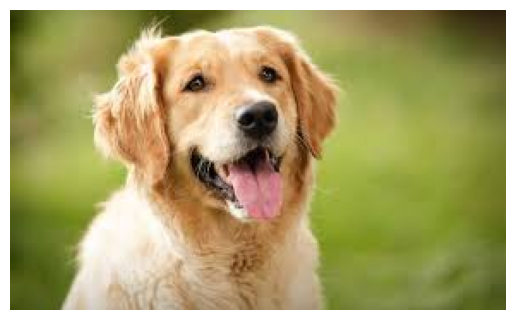

Prediction Score: 1.0
Predicted Class: Dog


In [21]:
# Cell 19: Upload and Predict a New Image

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

# Upload an image
uploaded = files.upload()

# Get the uploaded filename
image_path = list(uploaded.keys())[0]

# Load and resize image
image = load_img(image_path, target_size=(224, 224))

# Convert image to array
image_array = img_to_array(image)

# Add batch dimension
image_array = np.expand_dims(image_array, axis=0)

# Apply ResNet50 preprocessing
image_array = preprocess_input(image_array)

# Make prediction
prediction = model.predict(image_array)[0][0]

# Display image
plt.imshow(load_img(image_path))
plt.axis('off')
plt.show()

# Interpret prediction
if prediction >= 0.5:
    predicted_class = "Dog"
else:
    predicted_class = "Cat"

print("Prediction Score:", round(float(prediction), 4))
print("Predicted Class:", predicted_class)

In [22]:
# Cell 20: Final Results and Conclusion

print("=" * 55)
print("       TRANSFER LEARNING WITH RESNET50")
print("=" * 55)

print("\nDataset:")
print("  Classes: Cat and Dog")
print("  Training images: 2000")
print("  Validation images: 500")

print("\nModel:")
print("  Pretrained CNN: ResNet50")
print("  Pretrained weights: ImageNet")
print("  Input size: 224 x 224")
print("  Initial frozen layers: All ResNet50 layers")
print("  Fine-tuned layers: Last 20 ResNet50 layers")

print("\nPerformance:")
print(f"  Frozen Model Accuracy     : {accuracy_frozen * 100:.2f}%")
print(f"  Fine-Tuned Model Accuracy : {accuracy_finetune * 100:.2f}%")

print(f"\nAccuracy Change: {(accuracy_finetune - accuracy_frozen) * 100:+.2f}%")

print("\nConclusion:")
print("Transfer learning using a pretrained ResNet50 model")
print("was successfully implemented for Cats vs Dogs")
print("classification. Initially, the pretrained CNN layers")
print("were frozen and only the new classification layers")
print("were trained. The last 20 layers were then unfrozen")
print("and fine-tuned with a smaller learning rate.")
print("The performance of both approaches was compared.")
print("=" * 55)

       TRANSFER LEARNING WITH RESNET50

Dataset:
  Classes: Cat and Dog
  Training images: 2000
  Validation images: 500

Model:
  Pretrained CNN: ResNet50
  Pretrained weights: ImageNet
  Input size: 224 x 224
  Initial frozen layers: All ResNet50 layers
  Fine-tuned layers: Last 20 ResNet50 layers

Performance:
  Frozen Model Accuracy     : 98.40%
  Fine-Tuned Model Accuracy : 98.40%

Accuracy Change: +0.00%

Conclusion:
Transfer learning using a pretrained ResNet50 model
was successfully implemented for Cats vs Dogs
classification. Initially, the pretrained CNN layers
were frozen and only the new classification layers
were trained. The last 20 layers were then unfrozen
and fine-tuned with a smaller learning rate.
The performance of both approaches was compared.
